# 04 · SVM, Random Forest, XGBoost y SVD

**Jorge Javier Palma Martínez · ML1 FIUNA · 2026**

Protocolo: `rectangular-masked-v3-2026-11-22`.

Se muestran candidatos, ajustes y algoritmo SVD. La comparación utiliza train/validación; test no participa en estas decisiones.

Este cuaderno contiene el código ejecutable de la etapa, dividido en celdas con explicación. Ejecutar de arriba hacia abajo. Los notebooks se recorren del 01 al 06; los ajustes y las curvas pueden tardar varios minutos.

## 1. Librerías y ubicación del proyecto

Se cargan las bibliotecas utilizadas y se localiza la carpeta raíz. La misma celda funciona al abrir el notebook desde la raíz o desde `notebooks`. No entrena ningún modelo.

In [1]:
from pathlib import Path
import sys, json, hashlib, shutil, time, warnings, copy
import numpy as np
import pandas as pd
import cv2
import joblib
import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import display, Image

ROOT = next(
    p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src/workflow.py").exists()
)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    auc,
    cohen_kappa_score,
)
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.decomposition import PCA
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.model_selection import StratifiedKFold, learning_curve
from sklearn.base import clone
from xgboost import XGBClassifier
from src.features import FEATURE_COUNT, PREPROCESSING_SPEC
from src.models import SVDSubspaceClassifier


## 2. Configuración y carpetas de salida

Se fija la semilla, el orden de las cinco etiquetas y las rutas de matrices, informes y modelos. Crear estas carpetas no modifica las radiografías originales.

In [2]:
DATA = ROOT / "data/processed"
REPORTS = ROOT / "reports"
FIGURES = REPORTS / "figures"
MODELS = ROOT / "models"
LABELS = ["Normal", "Dudosa", "Leve", "Moderada", "Severa"]
SEED = 42
PROTOCOL = "rectangular-masked-v3-2026-11-22"
for folder in [DATA, REPORTS, FIGURES, MODELS]:
    folder.mkdir(parents=True, exist_ok=True)
print("Proyecto:", ROOT)
print("Protocolo:", PROTOCOL)


Proyecto: C:\Users\fliaP\Documents\Fiuna\7_semestre\ML1\ML1\proyecto-rodilla
Protocolo: rectangular-masked-v3-2026-11-22


## 3. Guardar resultados y mostrar las figuras

La primera función exporta JSON evitando NaN/Infinity. La segunda guarda cada gráfico y lo muestra dentro del notebook, para que el documento conserve código y salida al verse en GitHub.

In [3]:
def save_json(path, value):
    def finite(item):
        if isinstance(item, dict):
            return {k: finite(v) for k, v in item.items()}
        if isinstance(item, (list, tuple)):
            return [finite(v) for v in item]
        if isinstance(item, np.generic):
            item = item.item()
        if isinstance(item, float) and not np.isfinite(item):
            return None
        return item

    Path(path).write_text(
        json.dumps(
            finite(value), ensure_ascii=False, indent=2, allow_nan=False, default=str
        ),
        encoding="utf-8",
    )


def figure(name):
    path = FIGURES / name
    plt.savefig(path, dpi=180, bbox_inches="tight")
    plt.close()
    display(Image(filename=str(path)))


## 4. Leer las matrices y definir las métricas

El cargador rechaza matrices de otra versión. La función de evaluación calcula accuracy, balanced accuracy, F1 y precisión/recall macro. F1 macro es el criterio de selección; no se ajustan transformaciones con test.

In [4]:
def arrays():
    payload = np.load(DATA / "features_arrays.npz")
    if "protocol" not in payload or str(payload["protocol"]) != PROTOCOL:
        raise ValueError(
            "Matrices de otra versión; ejecutar antes el preprocesamiento."
        )
    return payload


def score(y, pred):
    return {
        "Accuracy (%)": round(accuracy_score(y, pred) * 100, 4),
        "Balanced Acc (%)": round(balanced_accuracy_score(y, pred) * 100, 4),
        "F1 Macro": round(f1_score(y, pred, average="macro", zero_division=0), 6),
        "F1 Weighted": round(f1_score(y, pred, average="weighted", zero_division=0), 6),
        "Precision Macro": round(
            precision_score(y, pred, average="macro", zero_division=0), 6
        ),
        "Recall Macro": round(
            recall_score(y, pred, average="macro", zero_division=0), 6
        ),
    }


a = arrays()
display({k: v.shape for k, v in a.items() if k.startswith("X_")})


{'X_train_tabular': (1103, 288),
 'X_train_flat': (1103, 2304),
 'X_val_tabular': (236, 288),
 'X_val_flat': (236, 2304),
 'X_test_tabular': (237, 288),
 'X_test_flat': (237, 2304)}

## 5. Bucle completo de entrenamiento y validación

Este es el código que recorre candidatos: toma train, ejecuta `fit`, predice validación, calcula métricas y guarda modelos y resultados. El escalador/selector de cada Pipeline se ajusta solo con train. La función no accede a las entradas de test.

In [5]:
def fit_candidates(specs, filename):
    a = arrays()
    rows = []
    fitted = {}
    for name, family, kind, model in specs:
        X = a[f"X_train_{kind}"]
        V = a[f"X_val_{kind}"]
        t = time.perf_counter()
        with warnings.catch_warnings():
            warnings.filterwarnings("ignore", category=FutureWarning)
            model.fit(X, a["y_train"])
        metrics = score(a["y_val"], model.predict(V))
        rows.append(
            dict(
                Modelo=name,
                family=family,
                input_kind=kind,
                **metrics,
                seconds=round(time.perf_counter() - t, 2),
            )
        )
        fitted[name] = model
        print(name, metrics["F1 Macro"], flush=True)
    table = pd.DataFrame(rows).sort_values("F1 Macro", ascending=False, kind="stable")
    save_json(REPORTS / filename, table.to_dict(orient="records"))
    joblib.dump(fitted, MODELS / (filename.replace(".json", "_candidates.joblib")))
    return table


## 6. Configuración de SVM y XGBoost

SVM usa RBF, gamma scale, pesos balanceados y semilla 42. XGBoost usa profundidad 4, learning rate 0,05 y submuestreo 0,8. En cinco clases hay cinco árboles por ronda.

In [6]:
def svc(C=10):
    return SVC(
        C=C, kernel="rbf", class_weight="balanced", probability=True, random_state=SEED
    )


def xgb(n=200):
    return XGBClassifier(
        n_estimators=n,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        eval_metric="mlogloss",
        random_state=SEED,
        n_jobs=2,
    )


## 7. Candidatos SVM

Se crean tres Pipelines con C=1,10,50. Cada uno contiene su propio StandardScaler, que se ajustará con train.

In [7]:
specs = []

for C in [1.0, 10.0, 50.0]:
    specs.append(
        (
            f"SVM RBF C={C:g}",
            "SVM",
            "tabular",
            Pipeline([("scale", StandardScaler()), ("clf", svc(C))]),
        )
    )


## 8. Candidatos de árboles y ensambles

Se agregan 100/200/300 rondas de XGBoost y cuatro configuraciones de Random Forest. El código explicita cantidad de árboles, hoja mínima y pesos del bosque.

In [8]:
for n in [100, 200, 300]:
    specs.append((f"XGBoost {n} rondas", "XGBoost", "tabular", xgb(n)))

for n, leaf in [(100, 1), (200, 1), (200, 2), (300, 2)]:
    specs.append(
        (
            f"Random Forest n={n} hoja={leaf}",
            "Random Forest",
            "tabular",
            RandomForestClassifier(
                n_estimators=n,
                min_samples_leaf=leaf,
                class_weight="balanced_subsample",
                n_jobs=2,
                random_state=SEED,
            ),
        )
    )

print("Candidatos:", [item[0] for item in specs])


Candidatos: ['SVM RBF C=1', 'SVM RBF C=10', 'SVM RBF C=50', 'XGBoost 100 rondas', 'XGBoost 200 rondas', 'XGBoost 300 rondas', 'Random Forest n=100 hoja=1', 'Random Forest n=200 hoja=1', 'Random Forest n=200 hoja=2', 'Random Forest n=300 hoja=2']


## 9. Entrenar SVM y ensambles

Se ajusta cada candidato y se mide F1 en validación. Esta es una celda de entrenamiento real y puede tardar.

In [9]:
table = fit_candidates(specs, "advanced_validation.json")

display(table)


SVM RBF C=1 0.629974
SVM RBF C=10 0.611277
SVM RBF C=50 0.613015
XGBoost 100 rondas 0.592011
XGBoost 200 rondas 0.617142
XGBoost 300 rondas 0.616885
Random Forest n=100 hoja=1 0.530875
Random Forest n=200 hoja=1 0.566662
Random Forest n=200 hoja=2 0.553305
Random Forest n=300 hoja=2 0.572851


,Modelo,family,input_kind,Accuracy (%),Balanced Acc (%),F1 Macro,F1 Weighted,Precision Macro,Recall Macro,seconds
0,SVM RBF C=1,SVM,tabular,64.4068,63.2627,0.629974,0.640820,0.635643,0.632627,1.02
4,XGBoost 200 rondas,XGBoost,tabular,64.4068,60.4372,0.617142,0.634151,0.657159,0.604372,17.42
5,XGBoost 300 rondas,XGBoost,tabular,64.8305,60.7580,0.616885,0.636708,0.653815,0.607580,24.59
2,SVM RBF C=50,SVM,tabular,63.1356,60.6825,0.613015,0.627764,0.627515,0.606825,0.92
1,SVM RBF C=10,SVM,tabular,63.1356,60.6785,0.611277,0.627305,0.622077,0.606785,0.94
3,XGBoost 100 rondas,XGBoost,tabular,63.5593,58.8926,0.592011,0.618023,0.635046,0.588926,7.19
9,Random Forest n=300 hoja=2,Random Forest,tabular,61.4407,57.1167,0.572851,0.599173,0.612850,0.571167,3.02
7,Random Forest n=200 hoja=1,Random Forest,tabular,61.8644,56.4414,0.566662,0.594966,0.615096,0.564414,2.45
8,Random Forest n=200 hoja=2,Random Forest,tabular,60.5932,56.3031,0.553305,0.582620,0.593924,0.563031,1.97
6,Random Forest n=100 hoja=1,Random Forest,tabular,57.6271,52.5220,0.530875,0.555944,0.578559,0.525220,1.17


## 10. Definir y ejecutar la clase del clasificador SVD

Esta celda de código ejecuta la definición completa: fit aprende medias y bases; residuals calcula los errores de proyección; predict elige el menor residuo y predict_proba transforma distancias en puntuaciones no calibradas. Definir la clase todavía no entrena un modelo. Se conserva la definición interactiva como SVDSubspaceClassifierNotebook para poder probarla. La siguiente celda usa la misma implementación desde src.models al crear los objetos que se guardan: así joblib puede cargarlos desde la API sin depender de una clase del kernel del notebook.

In [10]:
from sklearn.base import ClassifierMixin, BaseEstimator


class SVDSubspaceClassifier(ClassifierMixin, BaseEstimator):
    """Assign the nearest class-specific affine subspace by residual norm."""

    def __init__(self, k_components=30, temperature=0.25):
        self.k_components = k_components
        self.temperature = temperature

    def fit(self, X, y):
        X = np.asarray(X, dtype=np.float64)
        self.classes_ = np.unique(y)
        self.n_features_in_ = X.shape[1]
        self.means_, self.bases_ = {}, {}
        for cls in self.classes_:
            values = X[np.asarray(y) == cls]
            self.means_[cls] = values.mean(axis=0)
            basis, _, _ = np.linalg.svd(
                (values - self.means_[cls]).T, full_matrices=False
            )
            self.bases_[cls] = basis[:, : self.k_components]
        return self

    def residuals(self, X):
        output = []
        for cls in self.classes_:
            delta = np.asarray(X) - self.means_[cls]
            basis = self.bases_[cls][:, : self.k_components]
            output.append(np.linalg.norm(delta - (delta @ basis) @ basis.T, axis=1))
        return np.column_stack(output)

    def predict(self, X):
        return self.classes_[self.residuals(X).argmin(axis=1)]

    def predict_proba(self, X):
        distances = self.residuals(X)
        # Normalize each row independently, so a sample's output does not depend
        # on other samples present in the request. These scores are uncalibrated.
        scores = (
            -distances
            / (distances.mean(axis=1, keepdims=True) + 1e-9)
            / self.temperature
        )
        scores -= scores.max(axis=1, keepdims=True)
        exp = np.exp(scores)
        return exp / exp.sum(axis=1, keepdims=True)


SVDSubspaceClassifierNotebook = SVDSubspaceClassifier
print("Clase ejecutada:", SVDSubspaceClassifierNotebook.__name__)
print("Definir la clase no ejecuta fit; el ajuste ocurre en la siguiente celda.")


Clase ejecutada: SVDSubspaceClassifier
Definir la clase no ejecuta fit; el ajuste ocurre en la siguiente celda.


## 11. Ajustar el escalado y las bases SVD

Se importa explícitamente la clase guardable desde src.models, cuyo código se acaba de ejecutar y explicar. Se aprende el escalador con píxeles de train y solo se transforma validación. Se calculan bases de hasta 50 componentes por clase para reutilizarlas al probar rangos menores.

In [11]:
from src.models import SVDSubspaceClassifier

a = arrays()

scaler = StandardScaler()

X = scaler.fit_transform(a["X_train_flat"])

V = scaler.transform(a["X_val_flat"])

model = SVDSubspaceClassifier(50).fit(X, a["y_train"])


## 12. Comparar rangos del subespacio

Se evalúan k=5,10,20,30,50 sin ajustar con validación. La clase predicha minimiza la norma residual; las probabilidades softmax de este clasificador no son una calibración clínica.

In [12]:
rows = table.to_dict(orient="records")

saved = joblib.load(MODELS / "advanced_validation_candidates.joblib")

for k in [5, 10, 20, 30, 50]:
    model.k_components = k
    name = f"SVD k={k}"
    rows.append(
        dict(
            Modelo=name,
            family="SVD",
            input_kind="flat",
            **score(a["y_val"], model.predict(V)),
        )
    )
    saved[name] = Pipeline(
        [("scale", copy.deepcopy(scaler)), ("clf", copy.deepcopy(model))]
    )


## 13. Guardar la comparación completa

Se reúnen los quince candidatos avanzados, se ordenan por F1 de validación y se conservan los objetos ajustados para la selección posterior.

In [13]:
table = pd.DataFrame(rows).sort_values("F1 Macro", ascending=False, kind="stable")

save_json(REPORTS / "advanced_validation.json", table.to_dict(orient="records"))

joblib.dump(saved, MODELS / "advanced_validation_candidates.joblib")

display(table)


,Modelo,family,input_kind,Accuracy (%),Balanced Acc (%),F1 Macro,F1 Weighted,Precision Macro,Recall Macro,seconds
0,SVM RBF C=1,SVM,tabular,64.4068,63.2627,0.629974,0.640820,0.635643,0.632627,1.02
1,XGBoost 200 rondas,XGBoost,tabular,64.4068,60.4372,0.617142,0.634151,0.657159,0.604372,17.42
2,XGBoost 300 rondas,XGBoost,tabular,64.8305,60.7580,0.616885,0.636708,0.653815,0.607580,24.59
3,SVM RBF C=50,SVM,tabular,63.1356,60.6825,0.613015,0.627764,0.627515,0.606825,0.92
4,SVM RBF C=10,SVM,tabular,63.1356,60.6785,0.611277,0.627305,0.622077,0.606785,0.94
5,XGBoost 100 rondas,XGBoost,tabular,63.5593,58.8926,0.592011,0.618023,0.635046,0.588926,7.19
6,Random Forest n=300 hoja=2,Random Forest,tabular,61.4407,57.1167,0.572851,0.599173,0.612850,0.571167,3.02
7,Random Forest n=200 hoja=1,Random Forest,tabular,61.8644,56.4414,0.566662,0.594966,0.615096,0.564414,2.45
8,Random Forest n=200 hoja=2,Random Forest,tabular,60.5932,56.3031,0.553305,0.582620,0.593924,0.563031,1.97
9,Random Forest n=100 hoja=1,Random Forest,tabular,57.6271,52.5220,0.530875,0.555944,0.578559,0.525220,1.17


## 14. Espectros completos y umbral de Gavish-Donoho

Se muestra el código completo del análisis adicional. El escalador, las medias y las bases se ajustan solo con train. Gavish-Donoho calcula un umbral para reconstrucción bajo hipótesis de bajo rango y ruido blanco; no es un óptimo de clasificación. Se obtiene beta por separado para cada grado, porque sus cantidades de ejemplos son distintas.

In [14]:
from scipy.integrate import quad
from scipy.optimize import brentq


def gavish_donoho_threshold(singular_values, shape):
    """Unknown-noise hard threshold, using the Marchenko-Pastur median.

    This is a reconstruction criterion under low-rank plus white-noise
    assumptions, not an optimum for classification of these radiographs.
    """
    beta = min(shape) / max(shape)
    lower, upper = (1 - np.sqrt(beta)) ** 2, (1 + np.sqrt(beta)) ** 2

    def density(t):
        return np.sqrt(max(0, (upper - t) * (t - lower))) / (2 * np.pi * beta * t)

    median = brentq(
        lambda value: quad(density, lower, value)[0] - 0.5, lower + 1e-10, upper - 1e-10
    )
    coefficient = np.sqrt(
        2 * (beta + 1) + 8 * beta / (beta + 1 + np.sqrt(beta**2 + 14 * beta + 1))
    )
    omega = coefficient / np.sqrt(median)
    threshold = omega * np.median(singular_values)
    return dict(
        beta=float(beta),
        omega=float(omega),
        threshold=float(threshold),
        rank=int(np.count_nonzero(singular_values > threshold)),
    )


def fit_svd_diagnostics(X_train, y_train, labels, selected_k):
    """Fit the common scaler and full class spectra using train alone."""
    scaler = StandardScaler().fit(X_train)
    standardized = scaler.transform(X_train).astype(np.float64)
    classes, rows = {}, []
    for target, label in enumerate(labels):
        values = standardized[np.asarray(y_train) == target]
        mean = values.mean(axis=0)
        centered = (values - mean).T
        basis, singular, _ = np.linalg.svd(centered, full_matrices=False)
        linear = np.cumsum(singular) / singular.sum()
        variance = np.cumsum(singular**2) / np.sum(singular**2)
        gd = gavish_donoho_threshold(singular, centered.shape)
        classes[target] = dict(
            mean=mean,
            basis=basis,
            singular=singular,
            linear=linear,
            variance=variance,
            gd=gd,
        )
        rows.append(
            dict(
                target=target,
                label=label,
                train_images=len(values),
                selected_k=int(selected_k),
                variance_at_selected_k=float(variance[selected_k - 1]),
                k_90=int(np.searchsorted(variance, 0.90) + 1),
                k_95=int(np.searchsorted(variance, 0.95) + 1),
                gd_rank=gd["rank"],
                gd_threshold=gd["threshold"],
                gd_beta=gd["beta"],
                gd_omega=gd["omega"],
            )
        )
    return scaler, classes, pd.DataFrame(rows)


## 15. Resumen cuantitativo y rango elegido con validación

Se reutilizan los resultados del barrido k=5,10,20,30,50. No se crea una nueva búsqueda ni se consulta test. La tabla informa cuánta varianza conserva el k elegido y qué rangos alcanzan 90 % y 95 %. La suma normalizada de valores singulares se distingue de la energía cuadrática: esta última coincide con la varianza acumulada de las matrices centradas.

In [15]:
svd_validation = pd.read_json(REPORTS / "advanced_validation.json")
svd_validation = svd_validation[svd_validation.family == "SVD"].sort_values(
    "F1 Macro", ascending=False, kind="stable"
)
selected_k = int(svd_validation.iloc[0].Modelo.split("k=")[1])
diagnostic_scaler, svd_classes, svd_summary = fit_svd_diagnostics(
    a["X_train_flat"], a["y_train"], LABELS, selected_k
)
svd_summary.to_csv(REPORTS / "svd_diagnostics.csv", index=False)
display(svd_validation[["Modelo", "F1 Macro", "Accuracy (%)"]])
display(svd_summary)
print(
    "SVD elegido:", selected_k, "componentes. El modelo final sigue siendo SVM RBF C=1."
)


SVD elegido: 10 componentes. El modelo final sigue siendo SVM RBF C=1.


,Modelo,F1 Macro,Accuracy (%)
10,SVD k=10,0.462945,46.6102
11,SVD k=30,0.462007,49.1525
12,SVD k=50,0.441081,47.8814
13,SVD k=20,0.429032,47.4576
14,SVD k=5,0.398410,41.9492


,target,label,train_images,selected_k,variance_at_selected_k,k_90,k_95,gd_rank,gd_threshold,gd_beta,gd_omega
0,0,Normal,335,10,0.757236,39,74,99,19.030361,0.145399,1.682430
1,1,Dudosa,329,10,0.698521,52,95,96,21.879894,0.142795,1.678346
2,2,Leve,153,10,0.781829,32,56,43,28.761440,0.066406,1.549936
3,3,Moderada,142,10,0.778906,30,52,40,28.157994,0.061632,1.541179
4,4,Severa,144,10,0.687027,47,73,38,33.488652,0.062500,1.542779


## 16. Valores singulares, acumulación y F1 frente a k

El índice comienza en 1. Las curvas espectrales usan exclusivamente entrenamiento; el último panel muestra F1 macro de validación. Conservar más varianza no garantiza separar mejor las clases. Se señala k elegido por F1, aunque no alcance el 90 % de varianza. Tras centrar n imágenes, el rango no supera n-1; el último valor casi nulo no es evidencia de un corte anatómico o de ruido.

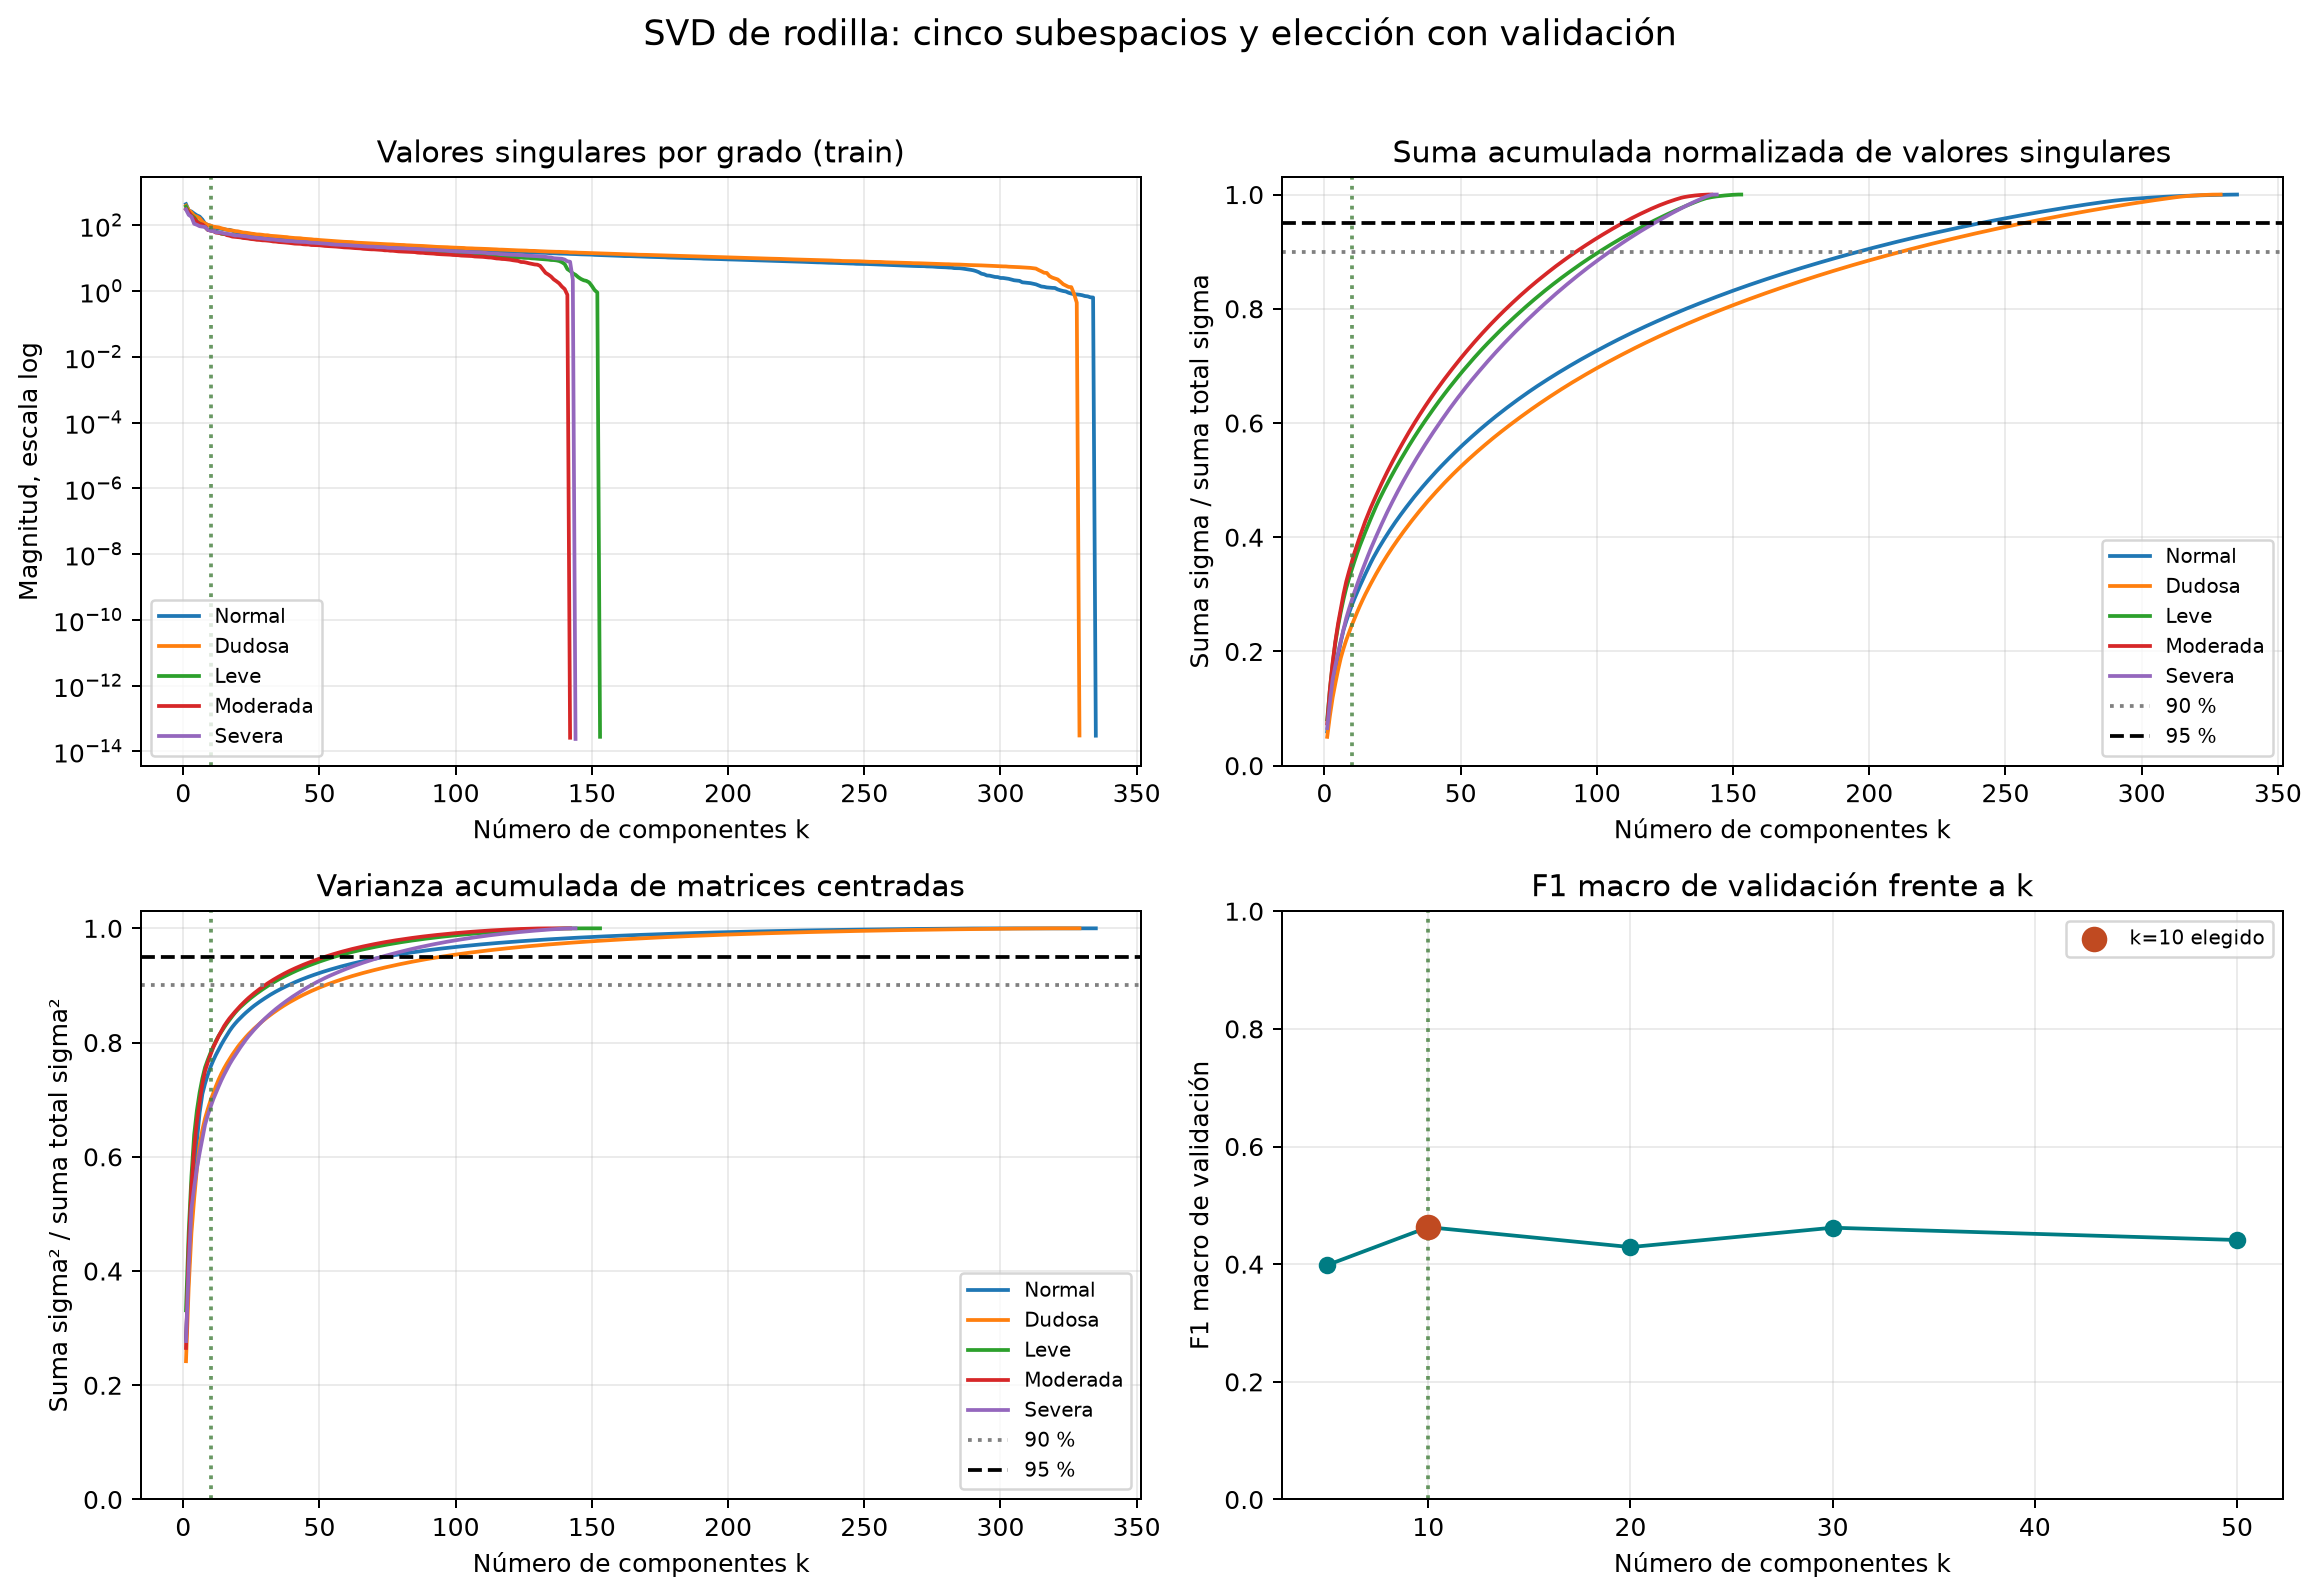

In [16]:
def plot_svd_selection(classes, labels, validation, selected_k):
    """Show spectral diagnostics and the already evaluated validation sweep."""
    fig, axes = plt.subplots(2, 2, figsize=(13, 9))
    colors = plt.get_cmap("tab10").colors
    for target, label in enumerate(labels):
        data = classes[target]
        k = np.arange(1, len(data["singular"]) + 1)
        axes[0, 0].semilogy(
            k, np.maximum(data["singular"], 1e-14), label=label, color=colors[target]
        )
        axes[0, 1].plot(k, data["linear"], label=label, color=colors[target])
        axes[1, 0].plot(k, data["variance"], label=label, color=colors[target])
    axes[0, 0].set_title("Valores singulares por grado (train)")
    axes[0, 0].set_ylabel("Magnitud, escala log")
    axes[0, 1].set_title("Suma acumulada normalizada de valores singulares")
    axes[0, 1].set_ylabel("Suma sigma / suma total sigma")
    axes[1, 0].set_title("Varianza acumulada de matrices centradas")
    axes[1, 0].set_ylabel("Suma sigma² / suma total sigma²")
    for ax in [axes[0, 1], axes[1, 0]]:
        ax.axhline(0.90, color="gray", linestyle=":", label="90 %")
        ax.axhline(0.95, color="black", linestyle="--", label="95 %")
        ax.set_ylim(0, 1.03)
    sweep = validation[validation.family == "SVD"].copy()
    sweep["k"] = sweep.Modelo.str.extract(r"k=(\d+)").astype(int)
    sweep = sweep.sort_values("k")
    axes[1, 1].plot(sweep.k, sweep["F1 Macro"], "o-", color="#007c83")
    chosen = sweep.loc[sweep.k == selected_k].iloc[0]
    axes[1, 1].scatter(
        [selected_k],
        [chosen["F1 Macro"]],
        s=85,
        color="#c04a21",
        zorder=5,
        label=f"k={selected_k} elegido",
    )
    axes[1, 1].set_title("F1 macro de validación frente a k")
    axes[1, 1].set_ylabel("F1 macro de validación")
    axes[1, 1].set_ylim(0, 1)
    for ax in axes.flat:
        ax.axvline(selected_k, color="#437f3c", linestyle=":", alpha=0.8)
        ax.set_xlabel("Número de componentes k")
        ax.grid(alpha=0.25)
        ax.legend(fontsize=8)
    fig.suptitle(
        "SVD de rodilla: cinco subespacios y elección con validación", fontsize=14
    )
    fig.tight_layout(rect=(0, 0, 1, 0.96))
    return fig


plot_svd_selection(svd_classes, LABELS, svd_validation, selected_k)
figure("svd_seleccion_dimension.png")


## 17. Interpretar el truncamiento teórico por grado

Se compara el rango teórico de Gavish-Donoho con el k elegido por validación. Las hipótesis del teorema no se verificaron en estos datos: la estandarización y el centrado afectan el ruido. El umbral se presenta como diagnóstico complementario y no cambia los parámetros entrenados.

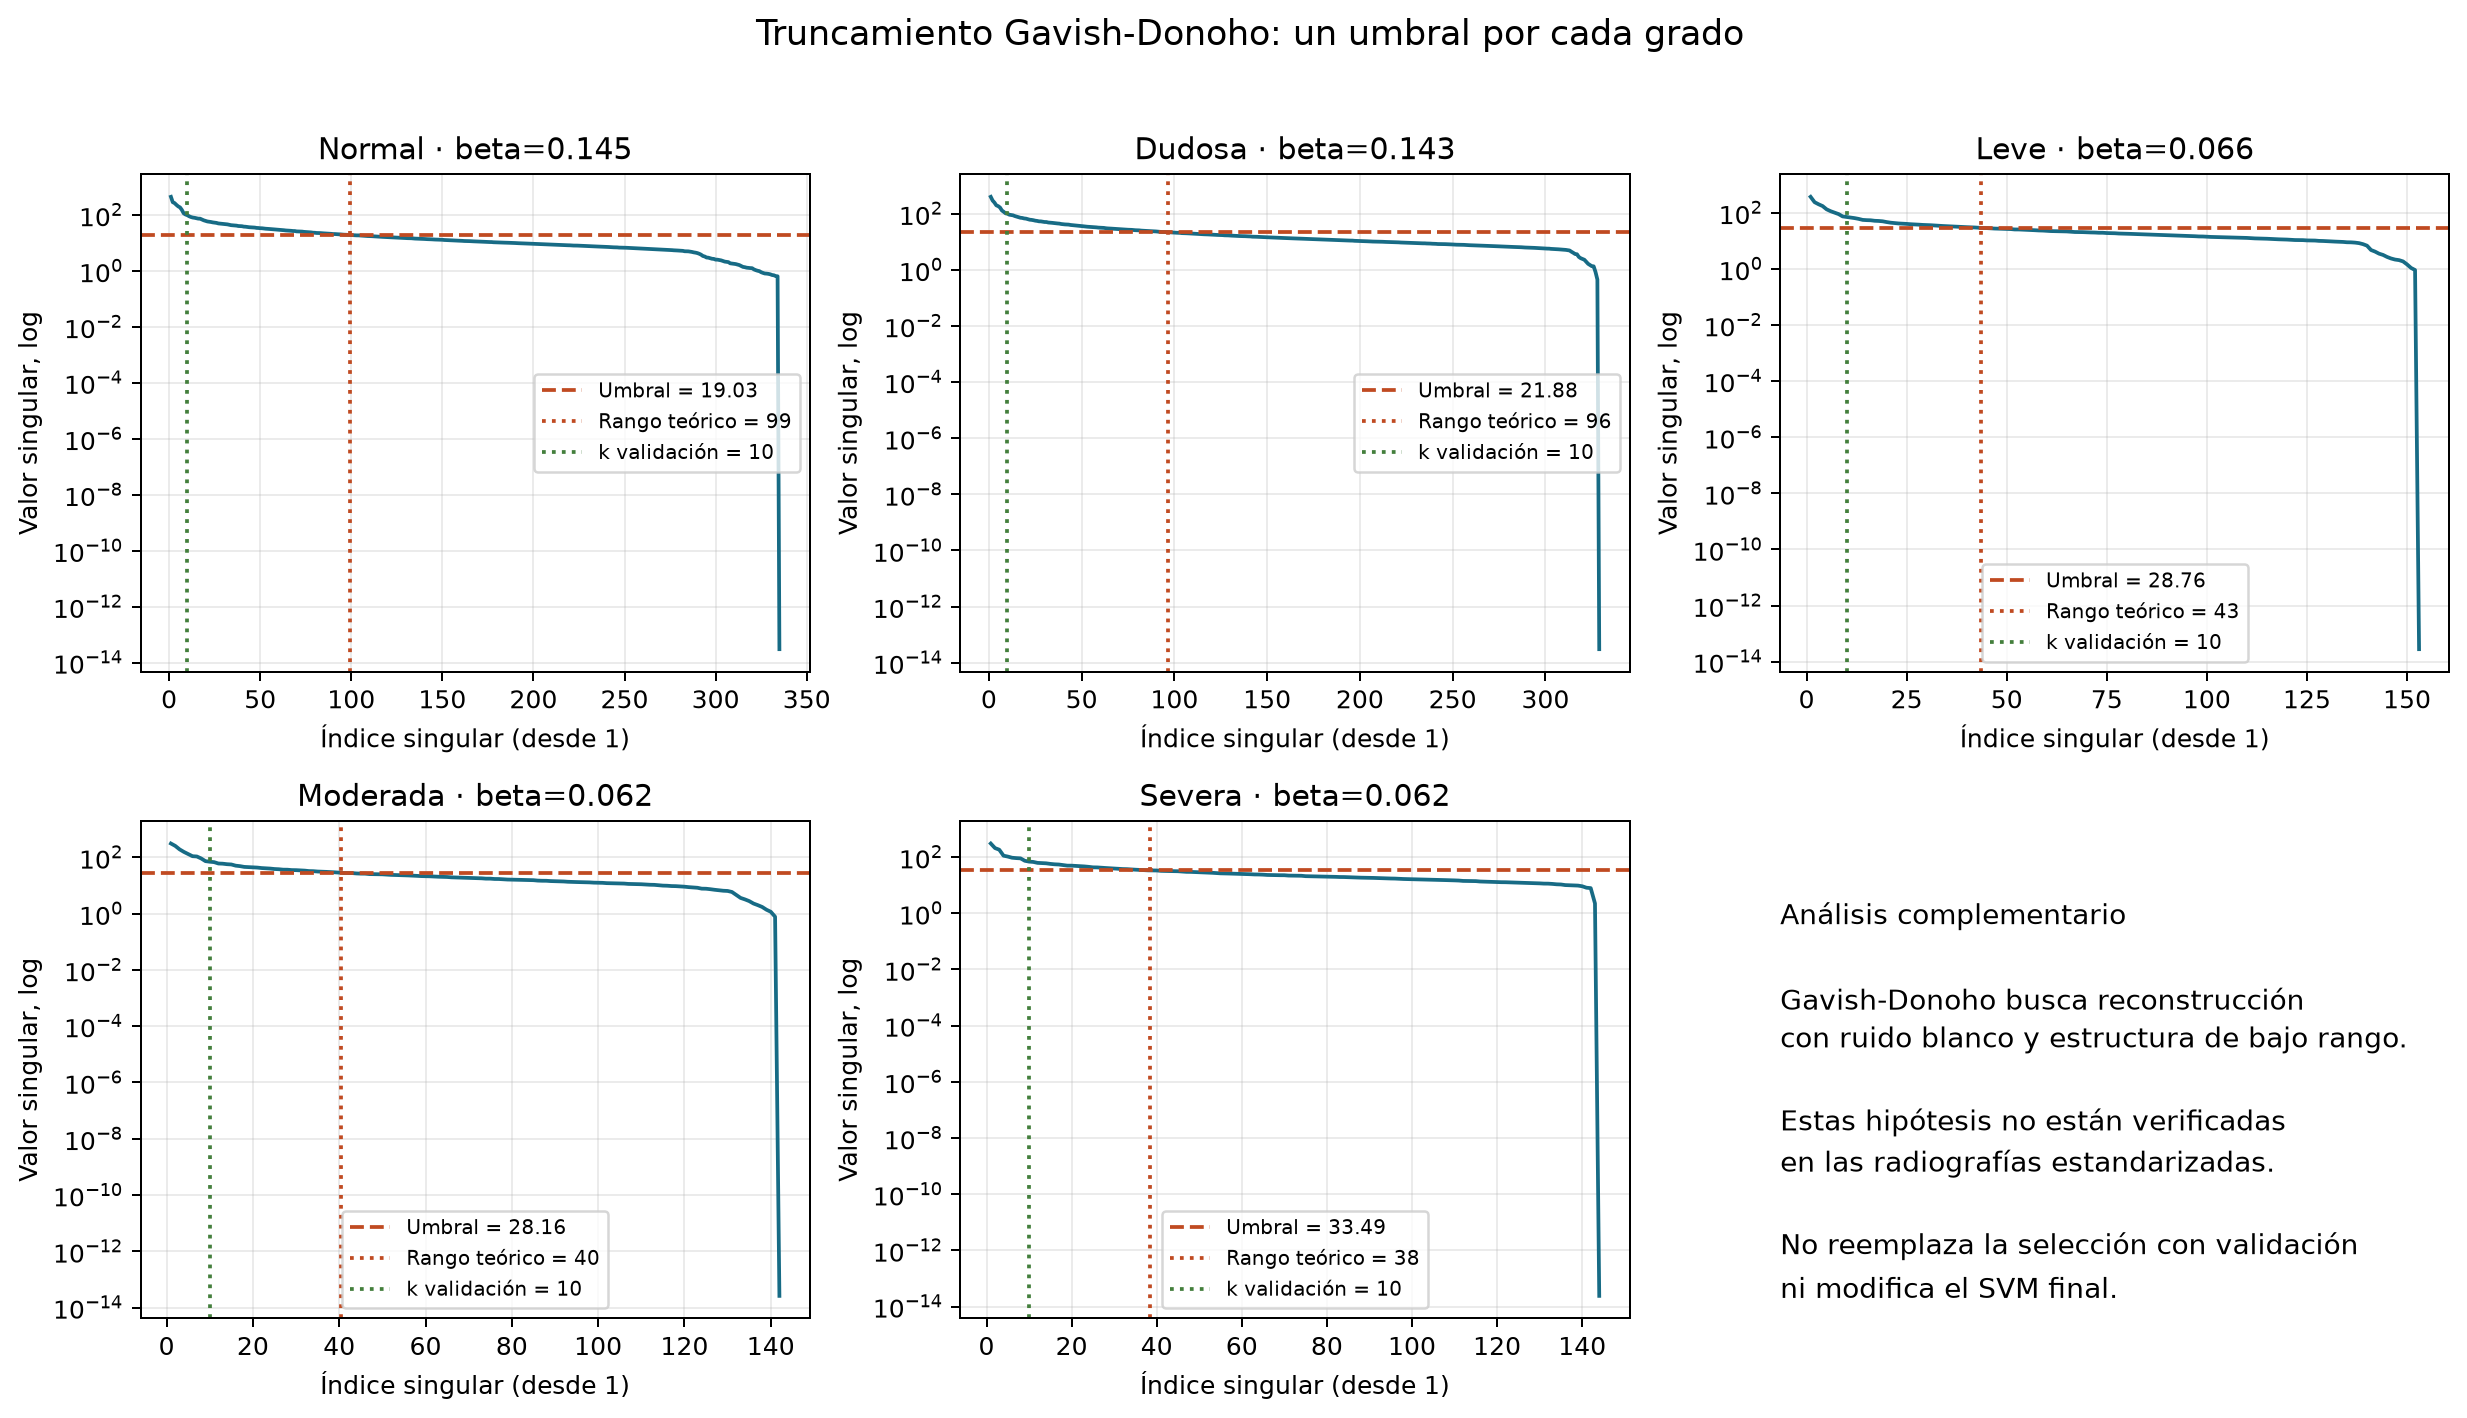

In [17]:
def plot_gavish_donoho(classes, labels, selected_k):
    """Display theoretical truncation separately for each class aspect ratio."""
    fig, axes = plt.subplots(2, 3, figsize=(14, 8))
    for target, label in enumerate(labels):
        ax = axes.flat[target]
        data, gd = classes[target], classes[target]["gd"]
        k = np.arange(1, len(data["singular"]) + 1)
        ax.semilogy(k, np.maximum(data["singular"], 1e-14), color="#176b85")
        ax.axhline(
            gd["threshold"],
            color="#c04a21",
            linestyle="--",
            label=f"Umbral = {gd['threshold']:.2f}",
        )
        ax.axvline(
            gd["rank"] + 0.5,
            color="#c04a21",
            linestyle=":",
            label=f"Rango teórico = {gd['rank']}",
        )
        ax.axvline(
            selected_k,
            color="#437f3c",
            linestyle=":",
            label=f"k validación = {selected_k}",
        )
        ax.set(
            title=f"{label} · beta={gd['beta']:.3f}",
            xlabel="Índice singular (desde 1)",
            ylabel="Valor singular, log",
        )
        ax.grid(alpha=0.25)
        ax.legend(fontsize=8)
    axes.flat[5].axis("off")
    axes.flat[5].text(
        0,
        0.85,
        "Análisis complementario\n\n"
        "Gavish-Donoho busca reconstrucción\ncon ruido blanco y estructura de bajo rango.\n\n"
        "Estas hipótesis no están verificadas\nen las radiografías estandarizadas.\n\n"
        "No reemplaza la selección con validación\nni modifica el SVM final.",
        transform=axes.flat[5].transAxes,
        fontsize=11,
        va="top",
        linespacing=1.5,
    )
    fig.suptitle("Truncamiento Gavish-Donoho: un umbral por cada grado", fontsize=14)
    fig.tight_layout(rect=(0, 0, 1, 0.96))
    return fig


plot_gavish_donoho(svd_classes, LABELS, selected_k)
figure("svd_gavish_donoho.png")


## 18. Medias, modos y reconstrucciones de radiografías

Se utiliza el primer ejemplo de validación de cada grado, sin elegir el más favorable. La media y la reconstrucción vuelven a unidades originales mediante inverse_transform. Los modos tienen signo arbitrario y están en coordenadas estandarizadas; no representan lesiones. Se reconstruye con la base de su etiqueta conocida solo para ilustrar geometría, no para medir exactitud. La inferencia real compara los cinco residuos sin conocer la etiqueta.

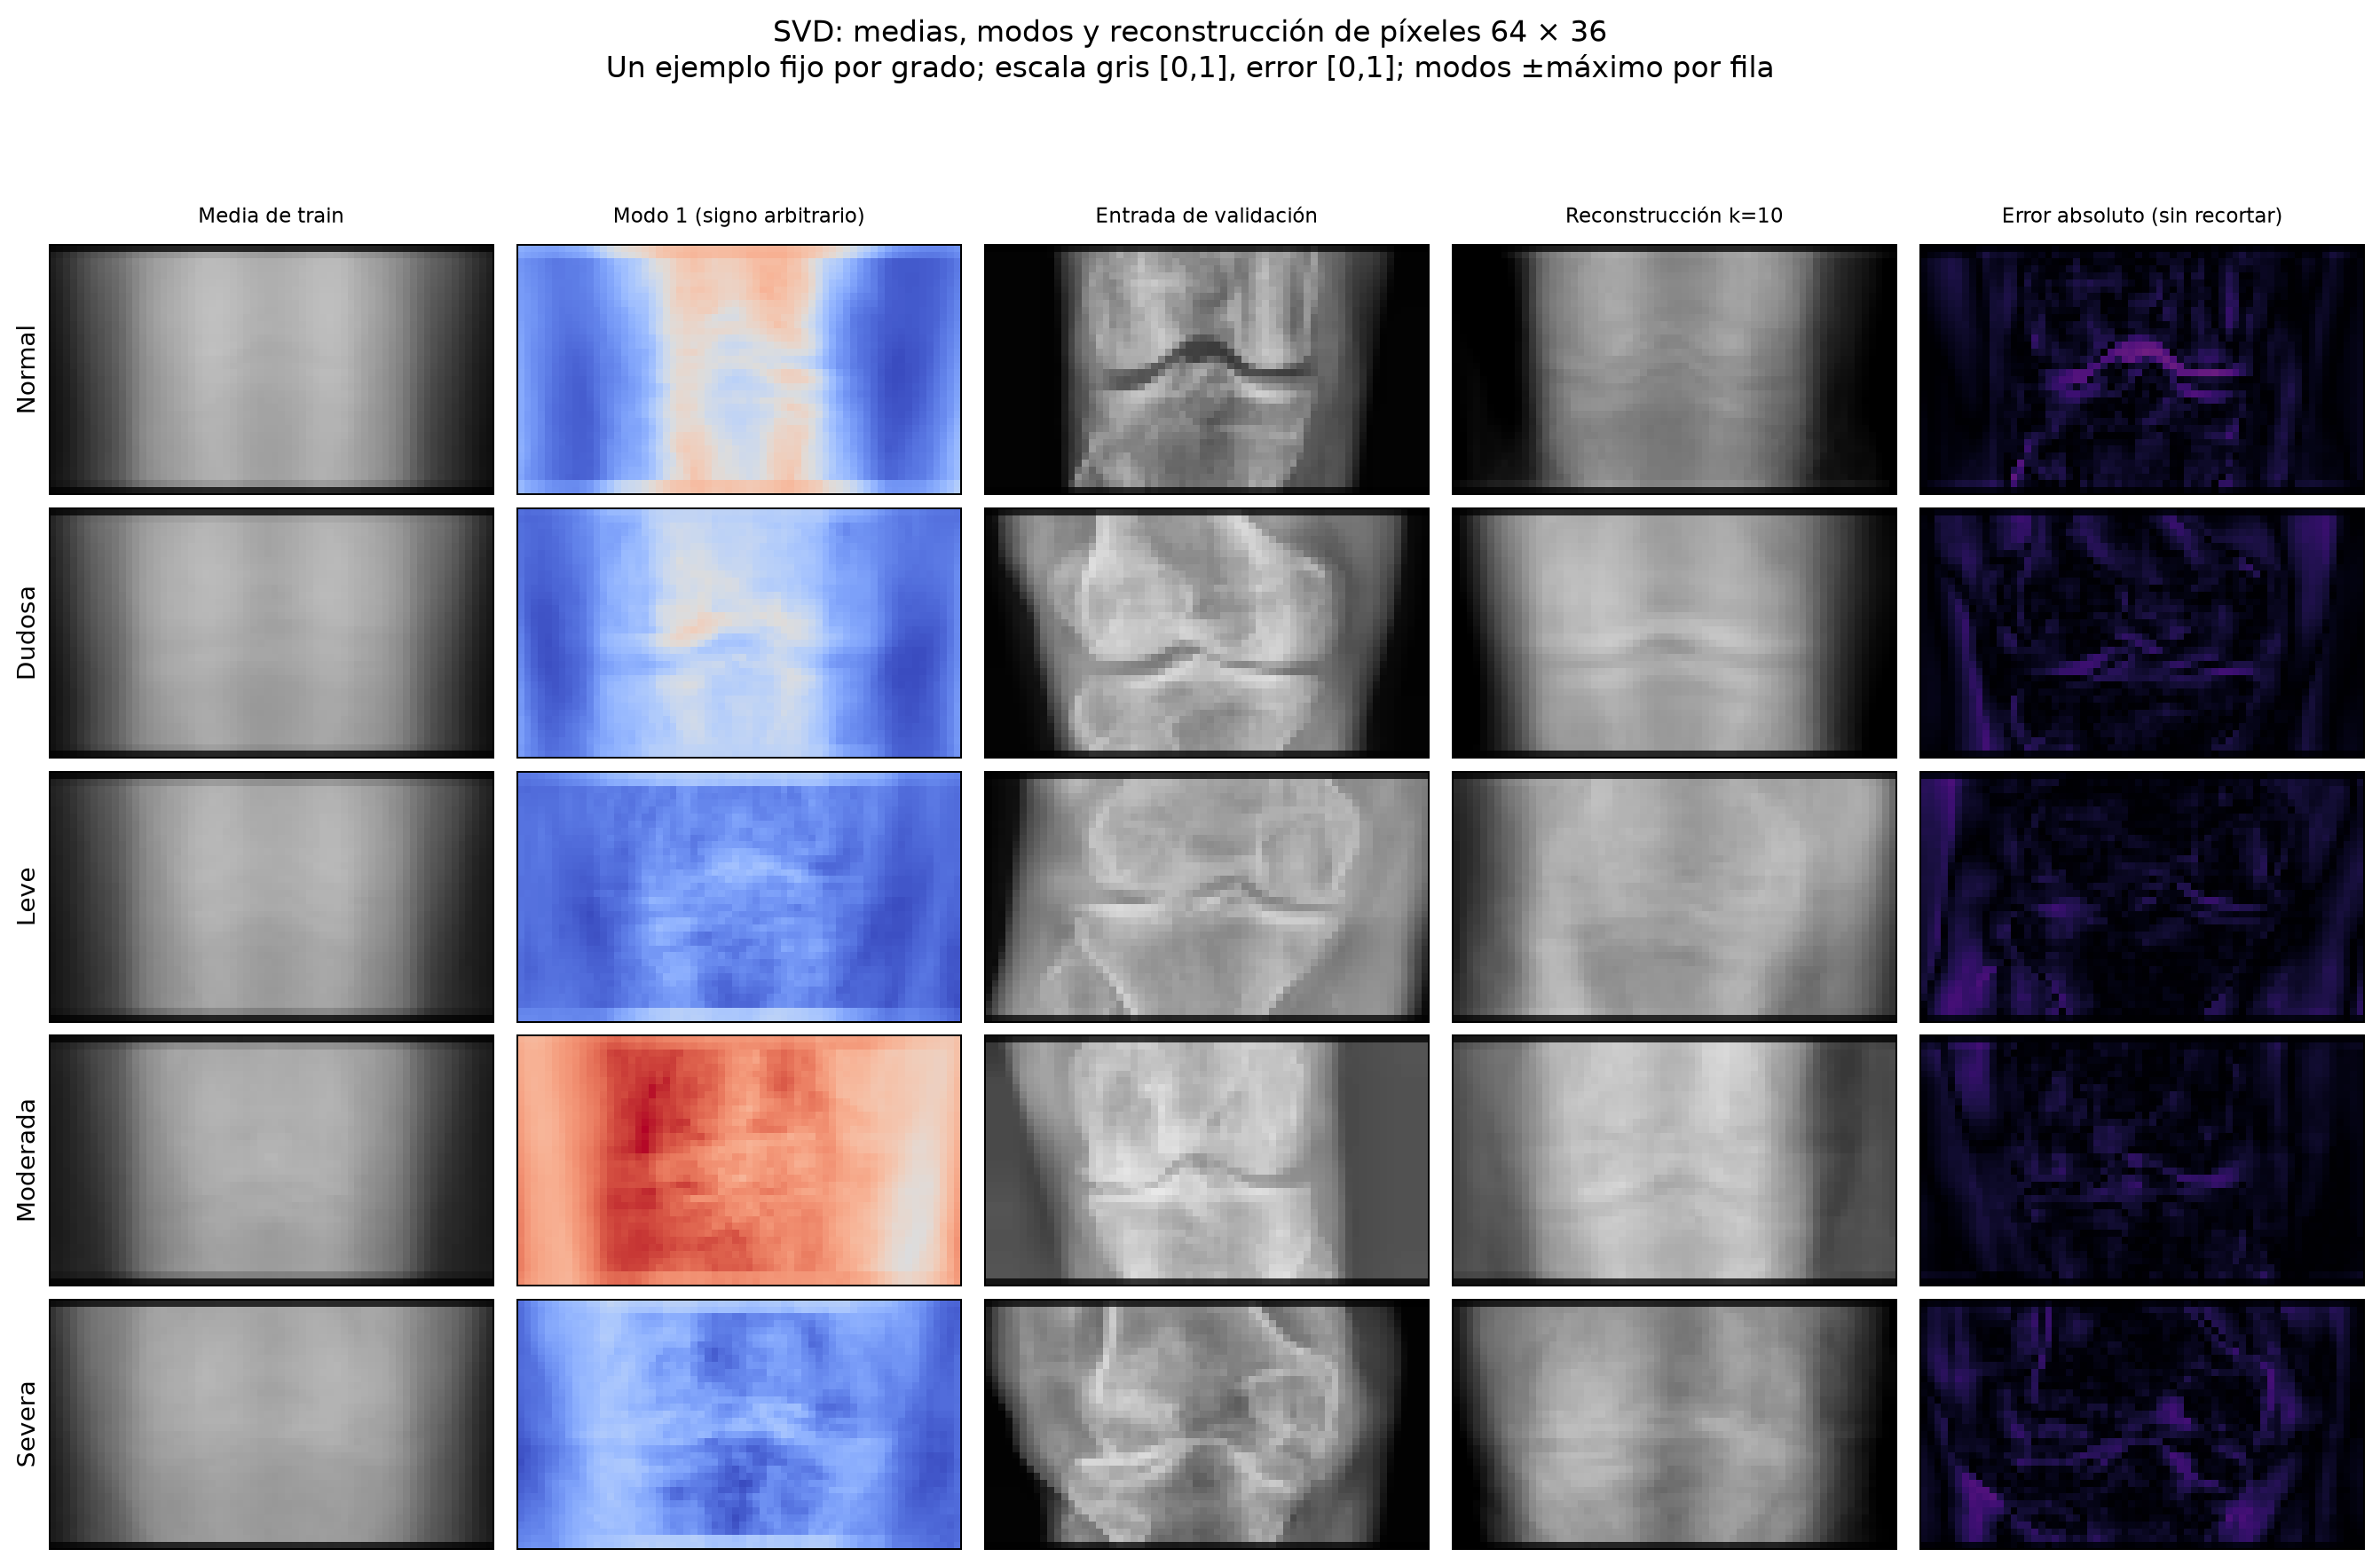

,target,label,validation_index,reconstruction_rmse
0,0,Normal,0,0.074832
1,1,Dudosa,2,0.073396
2,2,Leve,1,0.075113
3,3,Moderada,7,0.059333
4,4,Severa,3,0.079570


In [18]:
def plot_svd_reconstructions(
    scaler,
    classes,
    X_validation,
    y_validation,
    labels,
    selected_k,
    image_shape=(36, 64),
):
    """Use one fixed validation example per class for geometric illustration.

    Bases/means/scaler are learned on train only. Inverse scaling restores
    original pixel units for mean and reconstruction. Signed modes remain
    in standardized coordinates and are not anatomical structures.
    """
    fig, axes = plt.subplots(len(labels), 5, figsize=(15, 10))
    examples = []
    for target, label in enumerate(labels):
        index = int(np.flatnonzero(np.asarray(y_validation) == target)[0])
        raw = np.asarray(X_validation[index], dtype=np.float64)
        z = scaler.transform(raw[None])[0]
        data = classes[target]
        basis = data["basis"][:, :selected_k]
        delta = z - data["mean"]
        reconstructed_z = data["mean"] + (delta @ basis) @ basis.T
        reconstructed = scaler.inverse_transform(reconstructed_z[None])[0]
        mean = scaler.inverse_transform(data["mean"][None])[0]
        residual = np.abs(raw - reconstructed)
        mode = data["basis"][:, 0]
        bound = max(float(np.abs(mode).max()), 1e-12)
        items = [mean, mode, raw, reconstructed, residual]
        names = [
            "Media de train",
            "Modo 1 (signo arbitrario)",
            "Entrada de validación",
            f"Reconstrucción k={selected_k}",
            "Error absoluto (sin recortar)",
        ]
        for column, (values, name) in enumerate(zip(items, names)):
            ax = axes[target, column]
            if column == 1:
                ax.imshow(
                    values.reshape(image_shape),
                    cmap="coolwarm",
                    vmin=-bound,
                    vmax=bound,
                )
            elif column == 4:
                ax.imshow(values.reshape(image_shape), cmap="magma", vmin=0, vmax=1)
            else:
                ax.imshow(values.reshape(image_shape), cmap="gray", vmin=0, vmax=1)
            if target == 0:
                ax.set_title(name, fontsize=9, pad=10)
            ax.set_xticks([])
            ax.set_yticks([])
        axes[target, 0].set_ylabel(label, fontsize=11)
        examples.append(
            dict(
                target=target,
                label=label,
                validation_index=index,
                reconstruction_rmse=float(np.sqrt(np.mean(residual**2))),
            )
        )
    fig.suptitle(
        "SVD: medias, modos y reconstrucción de píxeles 64 × 36\n"
        "Un ejemplo fijo por grado; escala gris [0,1], error [0,1]; modos ±máximo por fila",
        fontsize=13,
    )
    fig.tight_layout(rect=(0, 0, 1, 0.93), h_pad=1.4)
    return fig, examples


_, svd_examples = plot_svd_reconstructions(
    diagnostic_scaler, svd_classes, a["X_val_flat"], a["y_val"], LABELS, selected_k
)
figure("svd_componentes_reconstruccion.png")
display(pd.DataFrame(svd_examples))
save_json(
    REPORTS / "svd_analysis.json",
    dict(
        protocol=PROTOCOL,
        fit_split="train",
        selection_split="validation",
        test_used=False,
        selected_k=selected_k,
        selected_validation_f1=float(svd_validation.iloc[0]["F1 Macro"]),
        final_model_unchanged=True,
        classes=svd_summary.to_dict(orient="records"),
        examples=svd_examples,
        references=[
            "https://github.com/carlobeni/Machine-Learning/tree/project-web/models",
            "https://arxiv.org/abs/1305.5870",
        ],
        limitation="Gavish-Donoho es un diagnóstico de reconstrucción; hipótesis de ruido blanco no verificadas.",
    ),
)


## 19. Cómo explicar el análisis en la defensa

El SVD comparado construye cinco subespacios sobre 2.304 píxeles. Sus curvas resumen la estructura de train. k=10 se eligió por F1 macro de validación entre cinco candidatos, no por inspección de test ni por un umbral fijo de varianza. Gavish-Donoho aborda reconstrucción bajo un modelo de ruido; no obliga a usar ese rango para clasificar. Estos gráficos explican el modelo SVD comparado; el pipeline final continúa con 288 descriptores, StandardScaler y SVM RBF C=1.

Referencias: [ejemplo de la cátedra](https://github.com/carlobeni/Machine-Learning/tree/project-web/models), [Gavish y Donoho](https://arxiv.org/abs/1305.5870), [NumPy SVD](https://numpy.org/doc/stable/reference/generated/numpy.linalg.svd.html).